# Human epithelial: cell-type annotation (stage 04c)

Every cluster of the re-integrated epithelial lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_human_epithelial.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/human_epithelial.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "human", "epithelial", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_human_epithelial.h5ad"
TABLE = REPO / "resources/annotations/human_epithelial.csv"
PANEL = ['CDH1', 'PAX8', 'WNT7A', 'MUC1', 'LGR5', 'FOXA2', 'LIF', 'SCGB1D2', 'FLT1', 'PECAM1', 'PDGFRA', 'PTPRC', 'ACTA2', 'PAEP', 'FOXJ1', 'MKI67']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,epithelial_cell,209,leiden_scVI_3.0,"CDH1 0.40; PAX8 0.69; EPCAM 0.39; FOXJ1 0.02 | top vs lineage: MAP2 0.58, CADM1 0.90, CASC15 0.77"
1,EXCLUDE,463,leiden_scVI_3.0,"EXCLUDE: fibroblast markers co-expressed; doublet med 0.00 (lineage q75 0.00), genes med 2200 (lineage q25 1664), co-expression 0.02"
2,epithelial_cell,230,leiden_scVI_3.0,"CDH1 0.44; PAX8 0.81; EPCAM 0.49; FOXJ1 0.02 | top vs lineage: BTG2 0.70, NR4A1 0.52, UCA1 0.67"
3,epithelial_cell,112,leiden_scVI_3.0,"CDH1 0.45; PAX8 0.72; EPCAM 0.25; FOXJ1 0.01 | top vs lineage: CASC15 0.89, CADM1 0.93, HIBCH 0.96"
4,epithelial_cell,127,leiden_scVI_3.0,"CDH1 0.43; PAX8 0.70; EPCAM 0.17; FOXJ1 0.00 | top vs lineage: CTNNA2 0.99, PGR 0.90, ADAMTS9 0.74"
5,epithelial_cell,300,leiden_scVI_3.0,"CDH1 0.43; PAX8 0.59; EPCAM 0.22; FOXJ1 0.00 | top vs lineage: ST3GAL5 0.78, NPAS3 0.96, PGR 0.92"
6,epithelial_cell,174,leiden_scVI_3.0,"CDH1 0.41; PAX8 0.61; EPCAM 0.32; FOXJ1 0.01 | top vs lineage: MID1 0.84, NPAS3 0.97, CTNNA2 0.94"
7,epithelial_cell,248,leiden_scVI_3.0,"CDH1 0.28; PAX8 0.70; EPCAM 0.29; FOXJ1 0.00 | top vs lineage: CTNNA2 0.94, LRRTM1 0.40"
8,epithelial_cell,107,leiden_scVI_3.0,"CDH1 0.39; PAX8 0.68; EPCAM 0.24; FOXJ1 0.00 | top vs lineage: ESR1 1.00, MTCL1 0.67, NPAS3 0.95"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

12179 nuclei; 51 clusters
{'epithelial_cell': 10608, 'EXCLUDE': 1480, 'epithelial_ciliated': 91}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

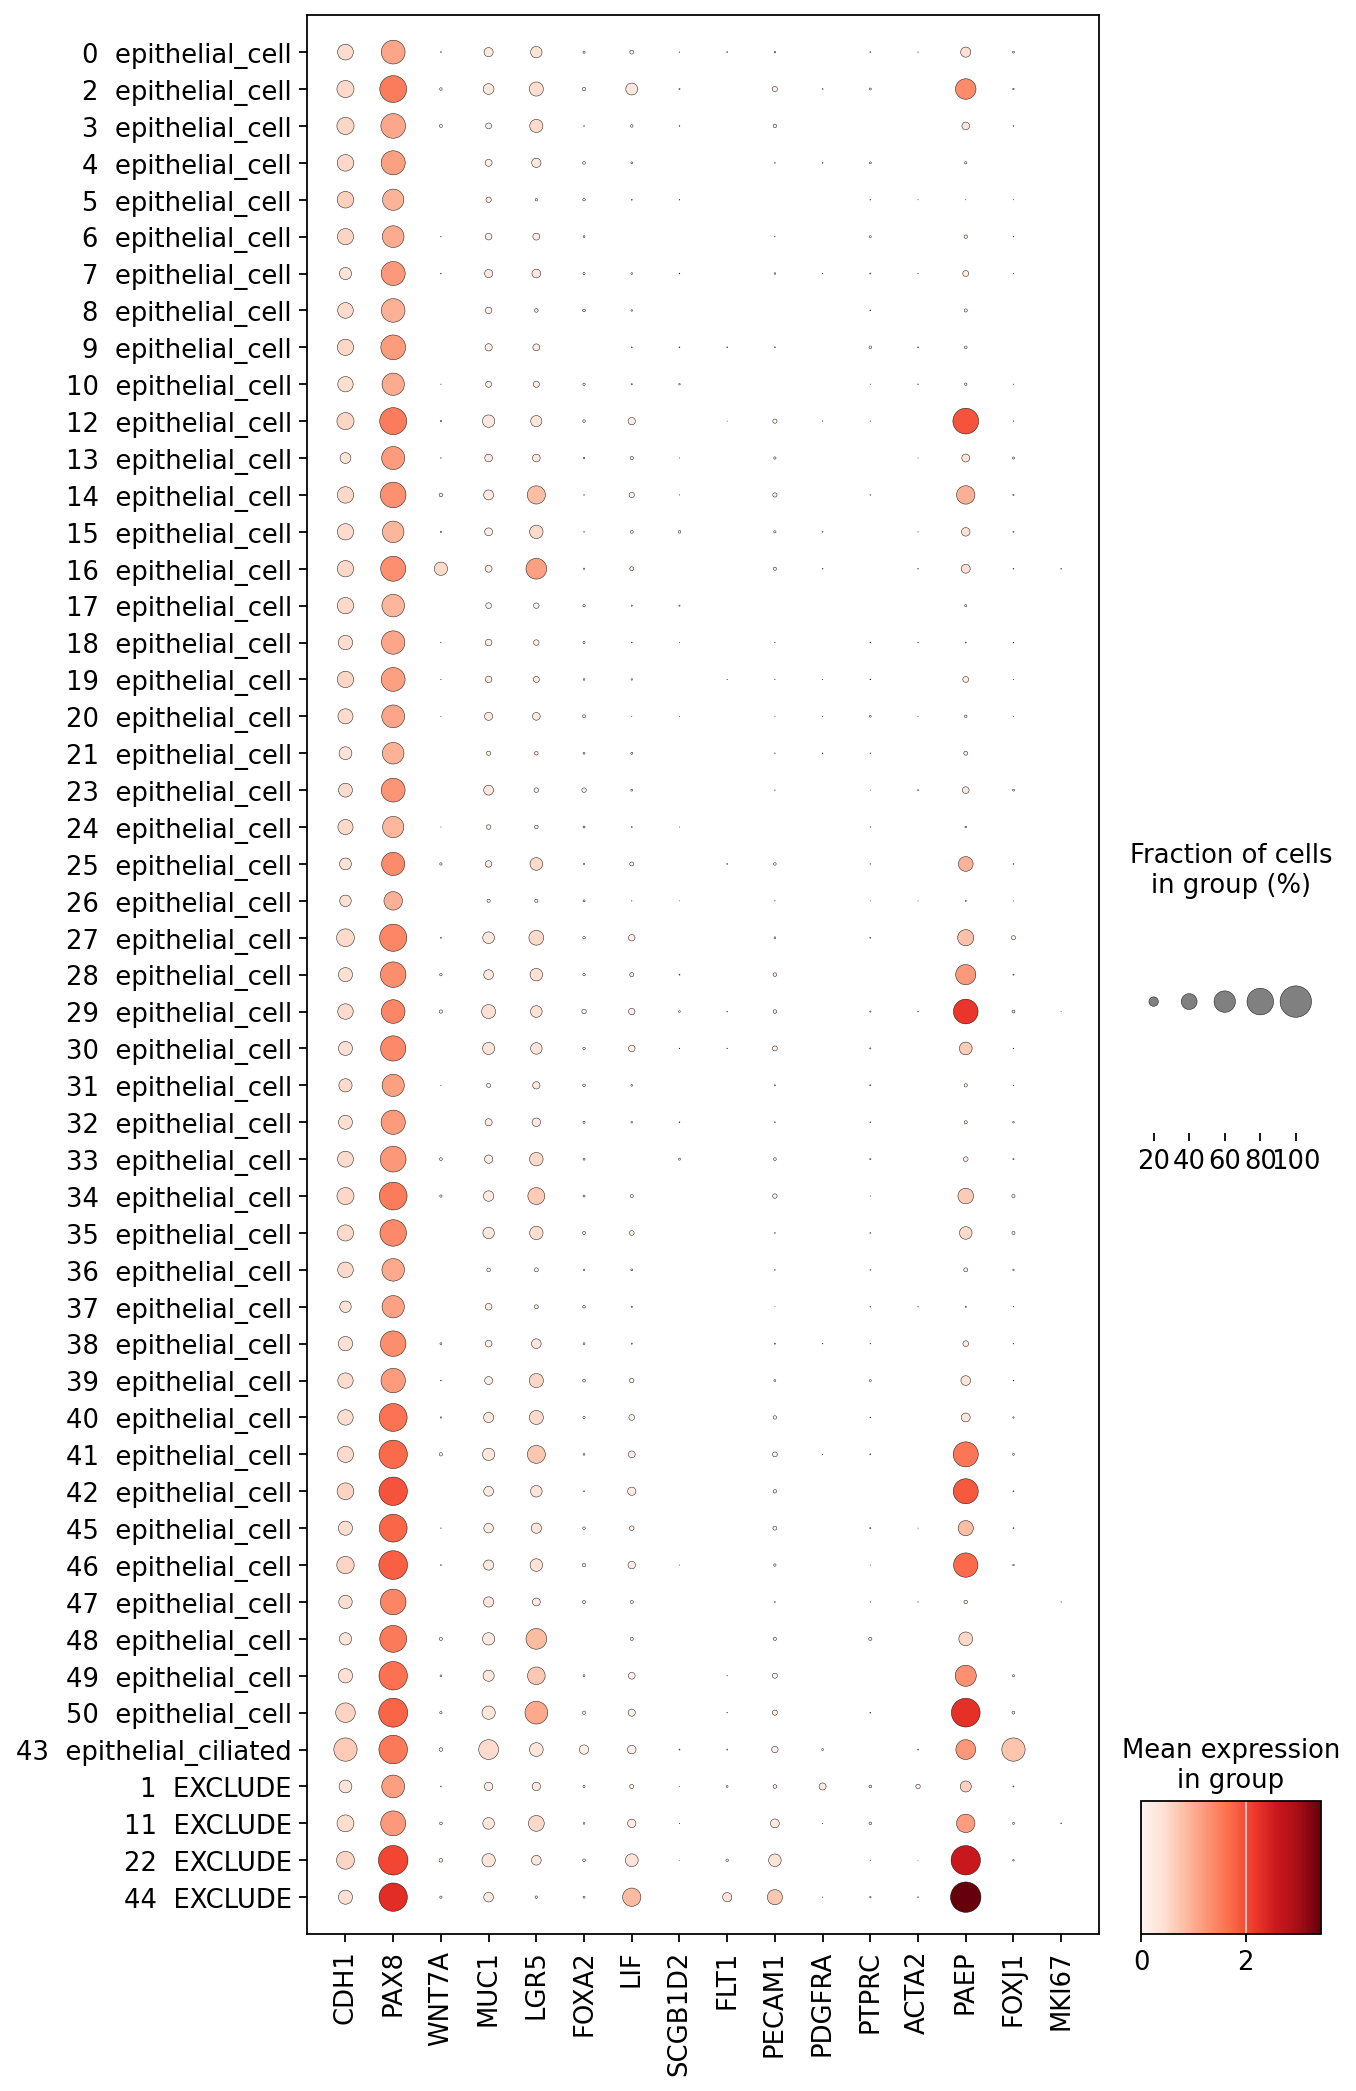

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference. A high doublet score together with markers of another lineage
(section 6) is what an EXCLUDE call rests on; a moderate score alone is not
(cycling clusters score around 1 throughout this dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,209,epithelial_cell,0.00,2619.0,5053.0
2,230,epithelial_cell,0.00,2873.5,5503.0
3,112,epithelial_cell,0.00,3060.5,6147.5
4,127,epithelial_cell,0.00,2520.0,4757.0
5,300,epithelial_cell,0.00,2250.5,3922.5
6,174,epithelial_cell,0.00,2391.0,4290.0
7,248,epithelial_cell,0.00,2177.5,3678.5
8,107,epithelial_cell,0.00,2662.0,5081.0
9,106,epithelial_cell,0.00,2352.0,4288.5


## 5. UMAP by cluster and by label

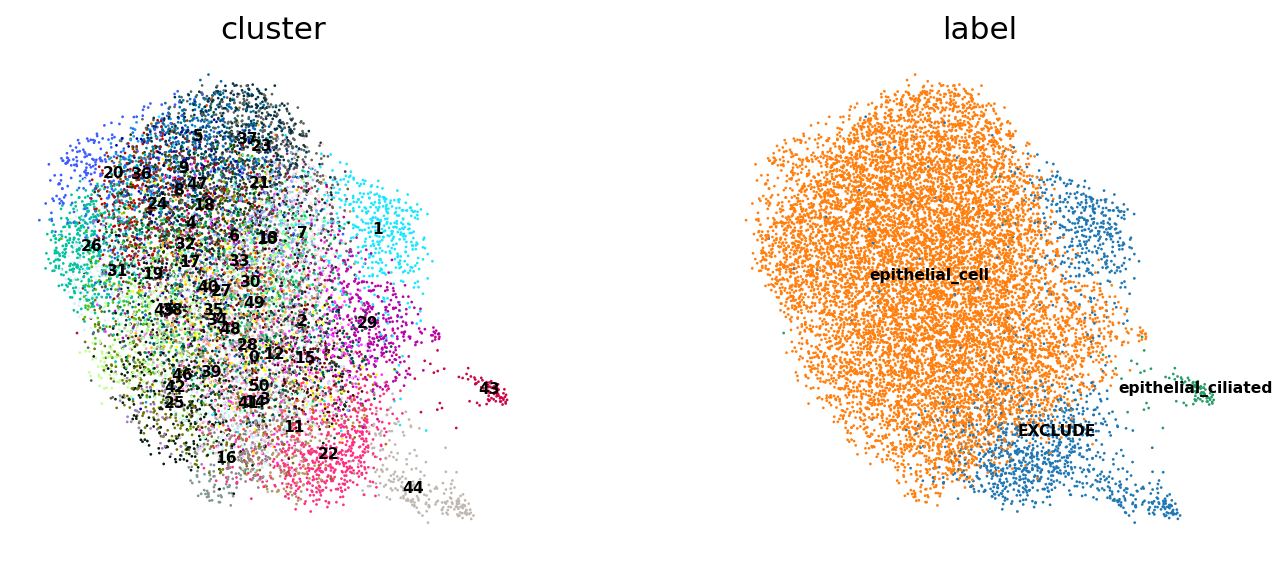

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,CDH1,PAX8,WNT7A,MUC1,LGR5,FOXA2,LIF,SCGB1D2,FLT1,PECAM1,PDGFRA,PTPRC,ACTA2,PAEP,FOXJ1,MKI67
1,0.30,0.65,0.01,0.17,0.17,0.03,0.07,0.0,0.02,0.06,0.14,0.04,0.07,0.25,0.01,0.00
11,0.44,0.74,0.04,0.26,0.40,0.02,0.17,0.0,0.00,0.18,0.00,0.04,0.00,0.49,0.03,0.01
22,0.47,0.92,0.06,0.32,0.21,0.04,0.30,0.0,0.03,0.29,0.00,0.00,0.00,0.91,0.02,0.00
44,0.34,0.87,0.03,0.21,0.03,0.03,0.48,0.0,0.19,0.38,0.00,0.02,0.01,0.96,0.00,0.00
lineage,0.38,0.72,0.02,0.19,0.22,0.03,0.08,0.0,0.01,0.05,0.01,0.01,0.01,0.32,0.02,0.00
